# Onset-locked EEG features + EM prior adaptation

**Code on Github:** https://github.com/cerepaulus/EEG-Sleep-Analysis

A small, fully classical pipeline: hand-built features, logistic regression, unsupervised prior adaptation on the test subject.

The ideas that matter:

1. **Every epoch starts at the annotated event onset**, so a spindle or K-complex sits in the first ~2 s. Features are band envelopes in short time bins around the onset, not the spectrum of the whole 30 s.
2. **Everything is normalised by the subject's own whole night.** Each epoch is an exact slice of the continuous `.mat` recording, so we can find it there and use night-level statistics, the pre-onset baseline and the surrounding sleep context.
3. **Class priors differ a lot between subjects** (spindles are 53% of S002's epochs but 15% of S003's). The S/K/REM mix of the test subject is re-estimated with EM on its unlabelled predictions.

No test labels and no information about the test-file row order are used (checked at the end).

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import butter, sosfiltfilt, hilbert, welch
from scipy.fft import next_fast_len
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

FS = 250
EPOCH_LEN = 7501
TRAIN_SUBJECTS = ["S001", "S002", "S003"]
TEST_SUBJECT = "S004"
CLASSES = np.array(["S", "K", "REM", "Son", "Soff", "A", "MS"])
N_ADAPTED = 3          # EM re-estimates the priors of the first 3 classes (S, K, REM)

# Find the competition files wherever they are mounted (case-insensitive, any sub-folder).
DATA_ROOT = Path("/kaggle/input") if Path("/kaggle/input").exists() else Path.cwd()
FILES = {p.name.lower(): p for p in DATA_ROOT.rglob("*") if p.is_file()}


def data_file(name):
    return FILES.get(name.lower())


assert data_file("S001_eeg_raw.mat"), "Add the competition dataset to this notebook (Add Input -> Competitions)."

## 1. Load the data and locate every epoch in the continuous recording

The provided `X.npy` epochs are exact slices of the raw recording, so an exact-match search gives each epoch's onset sample. For the training subjects this reproduces the timestamps in the label CSVs.

In [2]:
def load_raw(subject):
    return loadmat(data_file(f"{subject}_eeg_raw.mat"))["EEG"][0, 0]["data"][0].astype(np.float64)


def locate_epochs(raw, X):
    """Onset sample of each epoch row in the raw recording (epochs are exact slices of it)."""
    order = np.argsort(raw, kind="stable")
    sorted_raw = raw[order]
    onsets = np.empty(len(X), dtype=int)
    for i, x in enumerate(X):
        lo, hi = np.searchsorted(sorted_raw, x[0], "left"), np.searchsorted(sorted_raw, x[0], "right")
        match = [j for j in order[lo:hi] if np.array_equal(raw[j:j + len(x)], x)]
        if not match:
            raise ValueError(f"Epoch {i} not found in the raw recording")
        onsets[i] = match[0]
    return onsets


raws, onsets, labels = {}, {}, {}
for s in TRAIN_SUBJECTS + [TEST_SUBJECT]:
    raws[s] = load_raw(s)
    onsets[s] = locate_epochs(raws[s], np.load(data_file(f"{s}_X.npy")))
    y_path = data_file(f"{s}_y.npy")
    if y_path is not None:
        labels[s] = np.load(y_path)

pd.DataFrame({s: pd.Series(labels[s]).value_counts() for s in TRAIN_SUBJECTS}).reindex(CLASSES).fillna(0).astype(int)

,S001,S002,S003
S,210,565,123
K,199,227,378
REM,170,229,256
Son,29,20,30
Soff,18,10,14
A,22,13,20
MS,7,0,2


## 2. Why onset-locked features

Mean band envelope around the onset for the three big classes, pooled over the training subjects. Each value is the log ratio to that subject's whole-night median.

- **Spindles:** a sharp sigma burst in the first 0.5 s.
- **K-complexes:** a slow wave at onset, then a smaller sigma rise about 1 s later (the spindle that often follows a K-complex).
- **REM:** sigma well below the night median. It also has the largest slow deflection of all three, which is the eye movement itself picked up by the in-ear electrode.

Averaging over the whole 30 s washes most of this out.

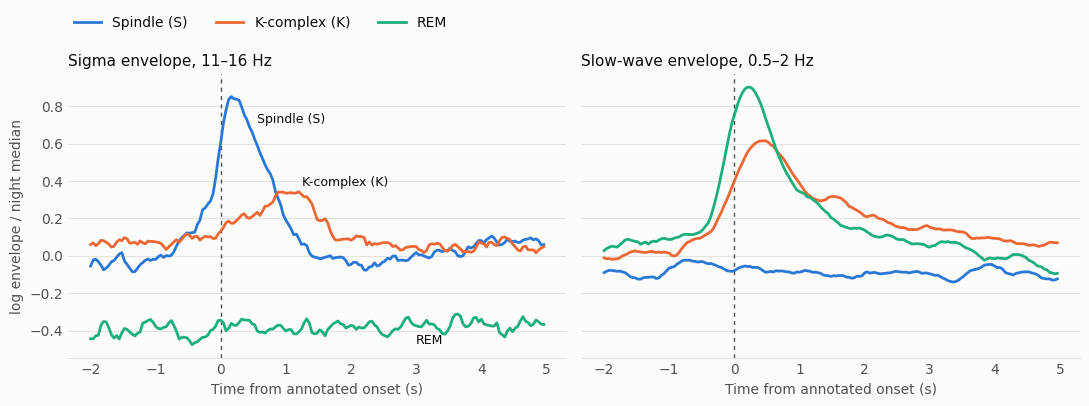

In [3]:
def bandpass(x, lo, hi):
    return sosfiltfilt(butter(4, [lo, hi], btype="band", fs=FS, output="sos"), x)


def envelope(x):
    return np.abs(hilbert(x, N=next_fast_len(len(x))))[:len(x)]


SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = {"S": ("#2a78d6", "Spindle (S)"), "K": ("#eb6834", "K-complex (K)"), "REM": ("#1baf7a", "REM")}
PANELS = [("Sigma envelope, 11–16 Hz", (11, 16)), ("Slow-wave envelope, 0.5–2 Hz", (0.5, 2))]
t = np.arange(-2, 5, 0.04)

profiles = {}
for title, (lo, hi) in PANELS:
    rows = {c: [] for c in SERIES}
    for s in TRAIN_SUBJECTS:
        env = envelope(bandpass(raws[s], lo, hi))
        idx = np.clip(onsets[s][:, None] + (t * FS).astype(int), 0, len(env) - 1)
        prof = np.log(env[idx] / np.median(env))
        for c in SERIES:
            rows[c].append(prof[labels[s] == c])
    profiles[title] = {c: np.concatenate(r).mean(0) for c, r in rows.items()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True, facecolor=SURFACE)
for ax, (title, _) in zip(axes, PANELS):
    ax.set_facecolor(SURFACE)
    ax.axvline(0, color=INK_2, lw=1, ls=(0, (3, 3)))
    for c, (color, name) in SERIES.items():
        ax.plot(t, profiles[title][c], color=color, lw=2, label=name)
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.set_xlabel("Time from annotated onset (s)", color=INK_2)
    ax.grid(axis="y", color=GRID, lw=0.8)
    ax.tick_params(colors=INK_2, length=0)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
axes[0].set_ylabel("log envelope / night median", color=INK_2)
# direct labels beside each sigma line, in ink colour (the legend carries the colour key)
sigma = profiles[PANELS[0][0]]
for c, (x, dy) in {"S": (0.55, 0.12), "K": (1.25, 0.06), "REM": (3.0, -0.1)}.items():
    axes[0].text(x, sigma[c][np.searchsorted(t, x)] + dy, SERIES[c][1], color=INK, fontsize=9)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", ncol=3, frameon=False,
           bbox_to_anchor=(0.06, 1.02), labelcolor=INK)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

## 3. Features

About 290 features per epoch, all computed from the continuous recording and normalised by whole-night statistics:

| Group | What it captures |
|---|---|
| `env_*` | 7 band envelopes in 15 time bins from −5 s to +30 s around the onset |
| `sal_*` | onset envelope relative to the same epoch's 3–30 s level (event salience) |
| `lf_*` | 0.5–4 Hz waveform from −1 to +3 s at 10 Hz, plus trough/peak values and latencies (K-complex shape) |
| `psd_*` | 30 s Welch spectrum relative to the night's median spectrum |
| `ctx_*` | band envelopes and amplitude from −120 s to +150 s (the sleep stage the event sits in) |
| `ssl_*`, `sfa_*`, `rsig_*`, `sig_*` | slow and fast sigma, sigma relative to broadband, spindle peak, latency and duration |
| `k_*` | K-complex trough depth and slope relative to the pre-onset baseline |
| `sdens_*` | spindle density in the surrounding minutes |
| `amp99_*`, `hjorth_*`, `hours_since_start` | movement artifacts, signal shape, time since recording start |

In [4]:
BANDS = {"d1": (0.5, 2), "d2": (2, 4), "th": (4, 8), "al": (8, 11), "sg": (11, 16), "b1": (16, 25), "b2": (25, 34)}
SIGMA_SUBBANDS = {"ssl": (11, 13.5), "sfa": (13.5, 16)}
ONSET_BINS = [(-5, -2), (-2, -1), (-1, -0.5), (-0.5, 0), (0, 0.25), (0.25, 0.5), (0.5, 0.75), (0.75, 1),
              (1, 1.5), (1.5, 2), (2, 3), (3, 5), (5, 10), (10, 20), (20, 30)]
SIGMA_BINS = [(-1, 0), (0, 0.25), (0.25, 0.5), (0.5, 0.75), (0.75, 1), (1, 1.5), (1.5, 2), (2, 3), (3, 30)]
CONTEXT_BINS = [(-120, -30), (-30, 0), (0, 30), (30, 60), (60, 150)]


def window(x, onset, t0, t1):
    """Slice of x from t0 to t1 seconds relative to onset (NaN if it falls outside the recording)."""
    i, j = max(onset + int(t0 * FS), 0), min(onset + int(t1 * FS), len(x))
    return x[i:j] if j > i else np.array([np.nan])


def extract_features(raw, onsets):
    """One row of features per epoch, every feature normalised by whole-night statistics."""
    feats, names = [], []

    def add(name, values):
        names.append(name)
        feats.append(np.asarray(values, dtype=float))

    def binned_log_ratio(prefix, sig, bins, ref):
        for t0, t1 in bins:
            add(f"{prefix}_{t0}_{t1}", [np.log(np.mean(window(sig, p, t0, t1)) / ref + 1e-6) for p in onsets])

    mad = np.median(np.abs(raw - np.median(raw))) * 1.4826

    # Onset-locked band envelopes, relative to the night's median envelope.
    envs = {band: envelope(bandpass(raw, lo, hi)) for band, (lo, hi) in BANDS.items()}
    night_median = {band: np.median(env) for band, env in envs.items()}
    for band, env in envs.items():
        binned_log_ratio(f"env_{band}", env, ONSET_BINS, night_median[band])

    # Event salience: onset envelope relative to the same epoch's 3-30 s level.
    for band, env in envs.items():
        late = np.array([np.mean(window(env, p, 3, 30)) for p in onsets])
        for t0, t1 in [(0, 0.5), (0.5, 1), (1, 2)]:
            add(f"sal_{band}_{t0}_{t1}", np.log([np.mean(window(env, p, t0, t1)) for p in onsets] / late))

    # Slow-wave waveform around the onset (K-complex shape), sampled at 10 Hz from -1 to 3 s.
    slow = bandpass(raw, 0.5, 4) / mad
    for t in np.arange(-1, 3, 0.1):
        add(f"lf_{t:.1f}", [slow[min(max(p + int(t * FS), 0), len(raw) - 1)] for p in onsets])
    for t0, t1 in [(0, 1), (0, 2), (1, 3)]:
        segs = [window(slow, p, t0, t1) for p in onsets]
        add(f"lfmin_{t0}_{t1}", [s.min() for s in segs])
        add(f"lfmax_{t0}_{t1}", [s.max() for s in segs])
        add(f"lfargmin_{t0}_{t1}", [s.argmin() / FS for s in segs])
        add(f"lfargmax_{t0}_{t1}", [s.argmax() / FS for s in segs])

    # Spectrum of the 30 s epoch relative to the night's median spectrum.
    starts = np.arange(0, len(raw) - EPOCH_LEN, EPOCH_LEN - 1)
    freqs, night_psd = welch(np.stack([raw[i:i + EPOCH_LEN] for i in starts]), fs=FS, nperseg=4 * FS, axis=1)
    epochs = np.stack([raw[p:p + EPOCH_LEN] for p in onsets])
    _, psd = welch(epochs, fs=FS, nperseg=4 * FS, axis=1)
    log_psd = np.log(psd + 1e-12) - np.median(np.log(night_psd + 1e-12), axis=0)
    edges = np.r_[np.arange(0.5, 16, 1), np.arange(16, 36, 2)]
    for lo, hi in zip(edges[:-1], edges[1:]):
        add(f"psd_{lo}_{hi}", log_psd[:, (freqs >= lo) & (freqs < hi)].mean(1))

    # Sleep-stage context from the continuous recording around the epoch.
    for t0, t1 in CONTEXT_BINS:
        for band, env in envs.items():
            add(f"ctx_{band}_{t0}_{t1}", [np.log(np.nanmean(window(env, p, t0, t1)) / night_median[band] + 1e-6)
                                          for p in onsets])
        add(f"ctx_amp_{t0}_{t1}", [np.log(np.nanpercentile(np.abs(window(raw, p, t0, t1)), 99) / mad + 1e-6)
                                   for p in onsets])

    # Movement / arousal artifacts inside the epoch, and Hjorth shape descriptors.
    for t0, t1 in [(0, 2), (2, 10), (10, 30)]:
        add(f"amp99_{t0}_{t1}", [np.log(np.percentile(np.abs(window(raw, p, t0, t1)), 99) / mad) for p in onsets])
    d1 = np.diff(epochs, axis=1)
    d2 = np.diff(d1, axis=1)
    mobility = np.sqrt(d1.var(1) / epochs.var(1))
    add("hjorth_mobility", mobility)
    add("hjorth_complexity", np.sqrt(d2.var(1) / d1.var(1)) / mobility)
    add("hours_since_start", onsets / FS / 3600)

    # Spindle detail: slow/fast sigma, sigma relative to broadband, spindle peak/latency/duration.
    for band, (lo, hi) in SIGMA_SUBBANDS.items():
        env = envelope(bandpass(raw, lo, hi))
        binned_log_ratio(band, env, SIGMA_BINS, np.median(env))
    sigma = envs["sg"]
    rel_sigma = sigma / (envelope(bandpass(raw, 0.5, 34)) + 1e-9)
    binned_log_ratio("rsig", rel_sigma, SIGMA_BINS, np.median(rel_sigma))
    sigma_med = night_median["sg"]
    segs = [window(sigma, p, -0.5, 3) / sigma_med for p in onsets]     # index 125 == onset
    add("sig_peak", [np.log(s[125:500].max()) for s in segs])
    add("sig_peak_lat", [s[125:500].argmax() / FS for s in segs])
    above = [s[125:] > 2 for s in segs]
    add("sig_dur2", [np.argmin(a) / FS if a[0] else 0 for a in above])
    add("sig_frac2_0_2", [a[:500].mean() for a in above])

    # K-complex trough relative to the pre-onset slow-wave baseline.
    slow_raw = slow * mad
    baseline = np.array([np.std(window(slow_raw, p, -3, 0)) for p in onsets]) + 1e-9
    segs = [window(slow_raw, p, 0, 2) for p in onsets]
    add("k_trough_rel", [s.min() / b for s, b in zip(segs, baseline)])
    add("k_ptp_rel", [np.ptp(s) / b for s, b in zip(segs, baseline)])
    add("k_slope", [np.max(np.abs(np.diff(s[::5]))) / b for s, b in zip(segs, baseline)])

    # Spindle density in the surrounding minutes.
    spindling = (sigma > 2 * sigma_med).astype(float)
    for t0, t1 in [(-60, 0), (0, 60), (-120, 120)]:
        add(f"sdens_{t0}_{t1}", [np.mean(w) if len(w) > 1 else np.nan
                                 for w in (window(spindling, p, t0, t1) for p in onsets)])

    return np.stack(feats, 1), names


features = {}
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)   # empty context windows at the night's edges -> NaN
    for s in TRAIN_SUBJECTS + [TEST_SUBJECT]:
        features[s], feature_names = extract_features(raws[s], onsets[s])
print(f"{len(feature_names)} features;", {s: f.shape[0] for s, f in features.items()}, "epochs")

286 features; {'S001': 655, 'S002': 1064, 'S003': 823, 'S004': 448} epochs


## 4. Model: logistic regression + EM prior adaptation

Strongly regularised logistic regression (C = 0.01) transferred best across subjects. Gradient boosting, SVM, MLP and LDA all did worse in leave-one-subject-out.

EM prior adaptation re-weights the posteriors towards the class mix the model itself sees in the unlabelled test subject. Only the S/K/REM split is re-estimated. With full EM, the rare classes (MS has 2–7 examples per subject) take over and the predictions collapse.

In [5]:
def make_model():
    return make_pipeline(SimpleImputer(), StandardScaler(), LogisticRegression(C=0.01, max_iter=5000))


def adapt_priors(P, prior, n_iter=100):
    """EM re-estimation of the test subject's S/K/REM priors (Saerens et al. 2002); rare classes keep the training prior."""
    target = prior.copy()
    for _ in range(n_iter):
        Q = P * (target / prior)
        Q /= Q.sum(1, keepdims=True)
        target = prior.copy()
        big = Q.mean(0)[:N_ADAPTED]
        target[:N_ADAPTED] = big / big.sum() * prior[:N_ADAPTED].sum()
    return Q


def fit_predict(F_train, y_train, F_test):
    """Posterior probabilities for F_test, columns in CLASSES order, after prior adaptation."""
    model = make_model().fit(F_train, y_train)
    P = np.zeros((len(F_test), len(CLASSES)))
    P[:, [list(CLASSES).index(c) for c in model.classes_]] = model.predict_proba(F_test)   # MS may be absent
    prior = np.array([(y_train == c).mean() for c in CLASSES]) + 1e-9
    return adapt_priors(P, prior)

## 5. Leave-one-subject-out validation

Train on two subjects, test on the third. This mimics the real task (transfer to an unseen subject) and is the only validation used for every design decision.

In [6]:
scores = {}
for test in TRAIN_SUBJECTS:
    train = [s for s in TRAIN_SUBJECTS if s != test]
    P = fit_predict(np.concatenate([features[s] for s in train]),
                    np.concatenate([labels[s] for s in train]), features[test])
    pred = CLASSES[P.argmax(1)]
    scores[test] = f1_score(labels[test], pred, average="weighted")
    print(f"\nTest {test}: weighted F1 = {scores[test]:.4f}  (rows = true, columns = predicted)")
    print(pd.DataFrame(confusion_matrix(labels[test], pred, labels=CLASSES), index=CLASSES, columns=CLASSES))
print(f"\nLOSO weighted F1: {np.mean(list(scores.values())):.4f}")


Test S001: weighted F1 = 0.8282  (rows = true, columns = predicted)
        S    K  REM  Son  Soff  A  MS
S     195   12    1    2     0  0   0
K      20  166    5    1     4  3   0
REM     2    6  156    6     0  0   0
Son     0    4    2   21     2  0   0
Soff    5    3    0    1     5  4   0
A       0   11    1    0     5  5   0
MS      1    1    0    4     1  0   0

Test S002: weighted F1 = 0.8366  (rows = true, columns = predicted)
        S    K  REM  Son  Soff  A  MS
S     461  100    4    0     0  0   0
K      47  178    0    0     1  1   0
REM     1    0  228    0     0  0   0
Son     0    3    6   11     0  0   0
Soff    0    2    2    0     5  1   0
A       0    5    3    0     0  5   0
MS      0    0    0    0     0  0   0

Test S003: weighted F1 = 0.7478  (rows = true, columns = predicted)
       S    K  REM  Son  Soff  A  MS
S     53   56   14    0     0  0   0
K     23  306   47    0     0  2   0
REM    0   12  241    0     0  3   0
Son    1    3    8   18     0  0   0


## 6. Train on all three subjects and write the submission

In [7]:
F_train = np.concatenate([features[s] for s in TRAIN_SUBJECTS])
y_train = np.concatenate([labels[s] for s in TRAIN_SUBJECTS])
P_test = fit_predict(F_train, y_train, features[TEST_SUBJECT])

submission = pd.DataFrame({"ID": np.arange(len(P_test)), "Marker": CLASSES[P_test.argmax(1)]})
submission.to_csv("submission.csv", index=False)
print(submission.Marker.value_counts().to_dict())
submission.head()

{'K': 208, 'S': 188, 'REM': 41, 'Son': 6, 'A': 4, 'Soff': 1}


,ID,Marker
0,0,S
1,1,S
2,2,S
3,3,S
4,4,S


## 7. Sanity check: predictions do not depend on the test-file order

The provided `X.npy` files are grouped by class (all S, then all K, …). A model that looked at neighbouring rows could exploit that. Here each epoch's features depend only on its own position in the raw recording, and EM only uses the set of test predictions. Shuffling the test rows must therefore shuffle the predictions in exactly the same way.

In [8]:
perm = np.random.default_rng(0).permutation(len(P_test))
P_shuffled = fit_predict(F_train, y_train, features[TEST_SUBJECT][perm])
print("order-invariant:", np.allclose(P_test[perm], P_shuffled))

order-invariant: True


## What I tried that did not help

| Idea | LOSO weighted F1 |
|---|---|
| Whole-epoch spectrum only (typical baseline) | ~0.43 |
| Gradient boosting / random forest / SVM / MLP on the same features | 0.71–0.77 |
| Per-subject z-scoring of features | 0.70 (depends on the class mix) |
| Training on the `0`/`1` suffix subclasses (S0, S1, …) and merging | no gain |
| 1D CNN on the onset-aligned raw signal (−2…+4 s) | 0.748 alone, +0.003 in an ensemble |
| Full (unrestricted) EM prior adaptation | collapses onto rare classes |

The remaining errors are mostly **S ↔ K** on events with a `0` suffix in the label files. Those events are barely visible in the in-ear signal (for example, `S0` events have near-baseline sigma power), so they are hard to separate with this single channel.